# Лабораторная работа № 1. Прикладная задача на табличных данных
Выполнил: Терехин А., группа 23ИВ1б.

**Вариант 1. Отток клиентов телеком-оператора** (Telco Customer Churn)

Ноутбук выполняется сверху вниз после перезапуска ядра. Результаты: `model.joblib`, `input_schema.json`,
`experiments.csv`, рисунки в `figures/`. Функции подготовки признаков — в модуле `features.py`.

In [1]:
import datetime as dt
import json
import os
import time
import warnings

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
import sklearn
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             log_loss, roc_auc_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

import features as F

warnings.filterwarnings('ignore', category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
C_FN, C_FP = 6000.0, 800.0      # пропуск уходящего клиента / скидка лояльному, ₽
N_JOBS = 4
os.makedirs('figures', exist_ok=True)
if os.path.exists('experiments.csv'):
    os.remove('experiments.csv')   # журнал пересоздаётся при каждом полном прогоне
print('sklearn', sklearn.__version__, '| lightgbm', lgb.__version__, '| optuna', optuna.__version__,
      '| shap', shap.__version__)

sklearn 1.9.1 | lightgbm 4.7.0 | optuna 5.0.0 | shap 0.54.1


## Шаг 1. Загрузка данных и постановка

Набор Telco Customer Churn (Kaggle, `blastchar/telco-customer-churn`; тот же файл опубликован IBM).
Если файла нет локально, он скачивается через `kagglehub`.

In [2]:
DATA_PATH = 'data/telco.csv'
if not os.path.exists(DATA_PATH):
    import kagglehub
    path = kagglehub.dataset_download('blastchar/telco-customer-churn')
    DATA_PATH = os.path.join(path, 'WA_Fn-UseC_-Telco-Customer-Churn.csv')

raw = pd.read_csv(DATA_PATH)
raw['target'] = (raw['Churn'] == 'Yes').astype(int)
print(raw.shape)
raw.head()

(7043, 22)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,target
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


**Постановка задачи**

| Элемент | Значение |
|---|---|
| Проблема | Оператор теряет выручку из-за ухода клиентов |
| Решение и исполнитель | Отдел удержания предлагает скидку клиентам с высоким риском ухода |
| Момент прогноза | Ежемесячный срез клиентской базы перед кампанией удержания |
| Объект | Один клиент (строка = клиент, повторов нет) |
| Целевая переменная и горизонт | `Churn` — клиент ушёл в течение следующего месяца после среза |
| Признаки | Всё, что известно на дату среза: демография, стаж, услуги, договор, способ оплаты, платежи |
| Основная метрика | ROC-AUC (доля ушедших ≈ 26,5 %, дисбаланс умеренный); дополнительно PR-AUC, Brier score |
| Цена ошибок | Пропуск уходящего клиента C_FN = 6000 ₽; лишняя скидка лояльному C_FP = 800 ₽ |
| Ограничения | Пакетный прогноз раз в месяц (время ответа не критично); решение объяснимо сотруднику; персональные данные (152-ФЗ), пол и возраст не должны быть основанием для отказа в скидке |

Теоретический порог для откалиброванной модели: t* = C_FP / (C_FP + C_FN) = 800 / 6800 ≈ 0,118.

## Шаг 2. Разведочный анализ

In [3]:
print('Размер:', raw.shape)
print('Типы:', raw.dtypes.astype(str).value_counts().to_dict())
blank_tc = raw['TotalCharges'].astype(str).str.strip().eq('')
print('TotalCharges — пустых строк:', blank_tc.sum(), '| tenure у них:', raw.loc[blank_tc, 'tenure'].unique())
print('Пропуски (NaN):', int(raw.isna().sum().sum()))
print('Уникальных customerID:', raw['customerID'].nunique())
print('Полных дубликатов без customerID:', raw.drop(columns='customerID').duplicated().sum())
print('Доля ушедших:', round(raw['target'].mean(), 4), '| ушедших:', raw['target'].sum())

Размер: (7043, 22)
Типы: {'str': 18, 'int64': 3, 'float64': 1}
TotalCharges — пустых строк: 11 | tenure у них: [0]
Пропуски (NaN): 0
Уникальных customerID: 7043
Полных дубликатов без customerID: 22
Доля ушедших: 0.2654 | ушедших: 1869


Ловушки варианта: `TotalCharges` читается как строка из-за 11 пустых значений — это клиенты с `tenure = 0`,
которые ещё не получили ни одного счёта; в `features.clean` они заполняются нулём (а не медианой), потому что
сумма начислений у них действительно 0. `customerID` — идентификатор, удаляется. 22 строки совпадают по всем
признакам, но это разные клиенты (разные ID, типичные тарифные пакеты), поэтому они оставлены.

In [4]:
df = F.clean(raw).assign(target=raw['target'])
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols_raw = [c for c in df.columns if c not in num_cols + ['target']]
display(df[num_cols].describe().T.round(2))

rows = []
for c in cat_cols_raw:
    g = df.groupby(c)['target'].agg(['size', 'mean'])
    for v, r in g.iterrows():
        rows.append({'признак': c, 'значение': v, 'доля строк, %': round(100 * r['size'] / len(df), 1),
                     'доля ушедших, %': round(100 * r['mean'], 1)})
cat_stats = pd.DataFrame(rows)
print('Категорий реже 1 %:', (cat_stats['доля строк, %'] < 1).sum())
cat_stats

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


Категорий реже 1 %: 0


,признак,значение,"доля строк, %","доля ушедших, %"
0,gender,Female,49.5,26.9
1,gender,Male,50.5,26.2
2,SeniorCitizen,No,83.8,23.6
3,SeniorCitizen,Yes,16.2,41.7
4,Partner,No,51.7,33.0
5,Partner,Yes,48.3,19.7
6,Dependents,No,70.0,31.3
7,Dependents,Yes,30.0,15.5
8,PhoneService,No,9.7,24.9
9,PhoneService,Yes,90.3,26.7


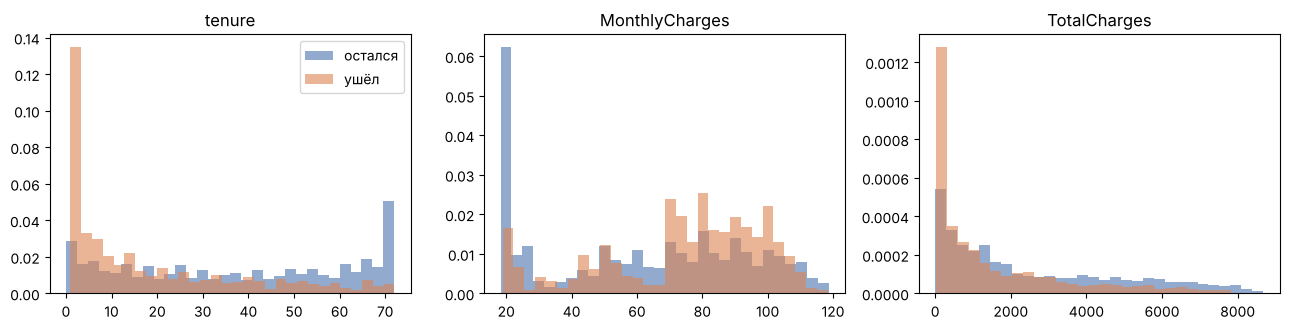

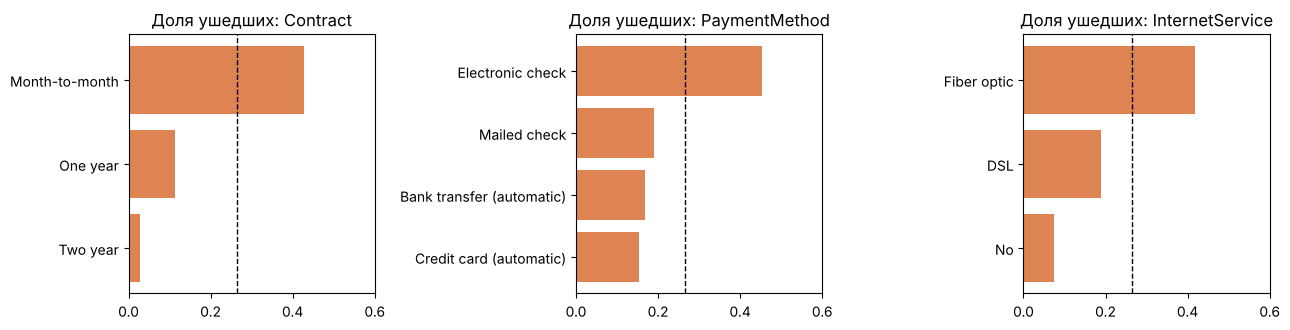

Медиана tenure: ушедшие 10.0 | оставшиеся 38.0
Доля ушедших среди клиентов с tenure <= 12: 0.474


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, num_cols):
    for t, lbl, col in [(0, 'остался', '#4C72B0'), (1, 'ушёл', '#DD8452')]:
        ax.hist(df.loc[df.target == t, c], bins=30, alpha=.6, density=True, label=lbl, color=col)
    ax.set_title(c)
axes[0].legend()
plt.tight_layout(); plt.savefig('figures/num_by_class.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, ['Contract', 'PaymentMethod', 'InternetService']):
    s = df.groupby(c)['target'].mean().sort_values()
    ax.barh(s.index.astype(str), s.values, color='#DD8452')
    ax.axvline(df.target.mean(), color='k', ls='--', lw=1)
    ax.set_title(f'Доля ушедших: {c}'); ax.set_xlim(0, .6)
plt.tight_layout(); plt.savefig('figures/cat_churn.png', dpi=150); plt.show()

print('Медиана tenure: ушедшие', df.loc[df.target == 1, 'tenure'].median(),
      '| оставшиеся', df.loc[df.target == 0, 'tenure'].median())
print('Доля ушедших среди клиентов с tenure <= 12:', round(df.loc[df.tenure <= 12, 'target'].mean(), 3))

**Выводы разведочного анализа.** 7043 клиента, 21 исходный столбец, пропусков нет (кроме 11 пустых `TotalCharges`),
редких категорий (< 1 %) нет. Доля ушедших 26,5 % — дисбаланс умеренный, поэтому основная метрика ROC-AUC.
- Ушедшие — в основном новые клиенты: медианный стаж 10 мес. против 38 у оставшихся; в первый год уходит 47 %.
- Договор помесячно — 42,7 % ушедших, на 1 год — 11,3 %, на 2 года — 2,8 %.
- Оплата электронным чеком — 45,3 % ушедших против 15–19 % у остальных способов.
- Оптоволокно — 41,9 % ушедших против 19,0 % у DSL; клиенты без интернета уходят реже всех (7,4 %).
- Отсутствие услуг защиты и техподдержки (`OnlineSecurity`, `TechSupport` = No) — около 42 % ушедших.
- Пенсионеры уходят чаще (41,7 % против 23,6 %), пол на отток почти не влияет (26,9 % против 26,2 %).

### Поиск утечек
ROC-AUC каждого признака по отдельности (функция из методических указаний). Категориальные признаки грубо
кодируются средним таргета — только для поиска утечек.

In [6]:
def leak_scan(df, target):
    scores = {}
    for col in df.columns.drop(target):
        x = df[col]
        if not pd.api.types.is_numeric_dtype(x):
            x = x.map(df.groupby(col)[target].mean())
        x = pd.to_numeric(x, errors='coerce').astype(float)
        x = x.fillna(x.median())
        if x.nunique() < 2:
            continue
        auc = roc_auc_score(df[target], x)
        scores[col] = max(auc, 1 - auc)
    return pd.Series(scores).sort_values(ascending=False)

leaks = leak_scan(df, 'target')
leaks_with_id = leak_scan(raw.drop(columns=['Churn']).assign(TotalCharges=df['TotalCharges']), 'target')
print('customerID (кодирование средним таргета):', round(leaks_with_id['customerID'], 3))
leaks.round(3).to_frame('ROC-AUC').head(10)

customerID (кодирование средним таргета): 1.0


,ROC-AUC
tenure,0.740
Contract,0.739
OnlineSecurity,0.705
TechSupport,0.703
InternetService,0.695
OnlineBackup,0.678
PaymentMethod,0.671
DeviceProtection,0.671
TotalCharges,0.650
StreamingMovies,0.621


Ни один признак не превышает порог 0,9. Самые сильные — `tenure` (0,740) и `Contract` (0,739) и связанные с ним
платежи; все они известны в момент среза. Отдельно показано, как выглядит «утечка через идентификатор»:
`customerID`, закодированный средним таргета, даёт ROC-AUC = 1,0, потому что каждый ID уникален и среднее
таргета по нему равно самому ответу. Это не информация о клиенте, а запоминание строки — поэтому ID удаляется.

Тонкое место набора: `tenure` и `TotalCharges` для ушедших клиентов зафиксированы на момент ухода, а не на
момент среза за месяц до него. Разница — один месяц, на качестве это почти не сказывается, но в эксплуатации
признаки нужно брать строго на дату среза (это требование к данным для ЛР2).

## Шаг 3. Разбиение и baseline
Стратифицированное разбиение: 20 % — отложенный тест, на обучающей части — стратифицированная 5-fold.

In [7]:
X = raw.drop(columns=['Churn', 'target'])
y = raw['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('train:', X_train.shape, 'доля ушедших', round(y_train.mean(), 4))
print('test: ', X_test.shape, 'доля ушедших', round(y_test.mean(), 4))

train: (5634, 20) доля ушедших 0.2654
test:  (1409, 20) доля ушедших 0.2654


In [8]:
LOG_COLUMNS = ['time', 'stage', 'trial', 'model', 'features', 'params', 'metric', 'n_folds', 'cv_mean', 'cv_std']

def log_experiment(model, features, params, scores, stage='baseline', trial=None, metric='roc_auc',
                   path='experiments.csv'):
    row = {'time': dt.datetime.now().isoformat(timespec='seconds'), 'stage': stage, 'trial': trial,
           'model': model, 'features': features, 'params': json.dumps(params, ensure_ascii=False, default=str),
           'metric': metric, 'n_folds': len(scores), 'cv_mean': float(np.mean(scores)), 'cv_std': float(np.std(scores))}
    pd.DataFrame([row], columns=LOG_COLUMNS).to_csv(path, mode='a', index=False, header=not os.path.exists(path))

preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
     make_column_selector(dtype_include='number')),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01)),
     make_column_selector(dtype_exclude='number')),
])

def make_logreg(add=F.clean):
    return make_pipeline(FunctionTransformer(add), preprocess,
                         LogisticRegression(max_iter=2000, C=1.0))

baselines = {'dummy': DummyClassifier(strategy='prior'),
             'logreg': make_logreg()}
baseline_cv = {}
for name, model in baselines.items():
    s_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    s_ap = cross_val_score(model, X_train, y_train, cv=cv, scoring='average_precision')
    baseline_cv[name] = (s_auc, s_ap)
    log_experiment(name, 'base', {}, s_auc)
    log_experiment(name, 'base', {}, s_ap, metric='average_precision')
    print(f'{name:7s} ROC-AUC {s_auc.mean():.4f} ± {s_auc.std():.4f} | PR-AUC {s_ap.mean():.4f} ± {s_ap.std():.4f}')

dummy   ROC-AUC 0.5000 ± 0.0000 | PR-AUC 0.2654 ± 0.0001


logreg  ROC-AUC 0.8461 ± 0.0126 | PR-AUC 0.6615 ± 0.0194


Логистическая регрессия даёт ROC-AUC 0,846 ± 0,013 — сильный baseline: в данных мало признаков, и связи с оттоком
почти монотонные. Константная модель даёт 0,5 (нижняя граница) и PR-AUC 0,265, равный доле ушедших.

## Шаг 4. Признаки и пайплайн
Все преобразования в `features.py` построчные (не используют статистик по выборке), поэтому одинаково
применяются к обучающим и новым данным и не дают утечки между фолдами. Кодирование категорий для LightGBM
(`CategoryAligner`) запоминает список категорий только на обучающей части.

Новые признаки (7 шт.):
1. `avg_monthly_charge` — средний фактический платёж за месяц: TotalCharges / tenure;
2. `charge_increase` — MonthlyCharges − avg_monthly_charge: насколько текущий тариф выше исторического;
3. `n_services` — число подключённых услуг (телефон, интернет и 7 доп. услуг);
4. `contract_payment` — сочетание типа договора и способа оплаты;
5. `fiber_no_protection` — оптоволокно без единой услуги защиты/поддержки;
6. `auto_payment` — автоматический платёж (банковский перевод или карта);
7. `tenure_bucket` — стаж в полных годах.

In [9]:
X_train_fe = F.add_features(X_train)
X_test_fe = F.add_features(X_test)
CAT_COLS = F.cat_columns(X_train_fe)
print(X_train_fe.shape, '| категориальных:', len(CAT_COLS))
X_train_fe[F.NEW_FEATURES].head()

(5634, 26) | категориальных: 17


,avg_monthly_charge,charge_increase,n_services,contract_payment,fiber_no_protection,auto_payment,tenure_bucket
3738,48.618571,0.581429,4,Month-to-month | Electronic check,0,0,2
3151,76.770000,-1.670000,3,Month-to-month | Mailed check,0,0,1
4860,45.411538,-4.861538,4,Two year | Mailed check,0,0,1
3867,73.296154,0.203846,6,Two year | Credit card (automatic),0,1,2
3810,44.550000,0.000000,2,Month-to-month | Electronic check,0,0,0


In [10]:
def make_estimator(kind, params, cat_cols=None):
    """Модель на признаках после add_features: подготовка категорий + бустинг."""
    if kind == 'lightgbm':
        return make_pipeline(F.CategoryAligner(), lgb.LGBMClassifier(**params))
    if kind == 'catboost':
        return make_pipeline(FunctionTransformer(F.to_catboost), F.CatBoostCat(params))
    raise ValueError(kind)

LGB_DEFAULT = dict(random_state=RANDOM_STATE, verbose=-1, n_jobs=N_JOBS)
# для абляции — умеренно регуляризованный LightGBM: на 5,6 тыс. строк параметры по умолчанию переобучаются
LGB_ABLATION = dict(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=40,
                    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, **LGB_DEFAULT)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

def cv_auc(kind, params, Xf, cv_=rcv):
    cat = F.cat_columns(Xf)
    return cross_val_score(make_estimator(kind, params, cat), Xf, y_train, cv=cv_, scoring='roc_auc')

t0 = time.time()
abl = {}
abl['исходные признаки'] = cv_auc('lightgbm', LGB_ABLATION, F.add_features(X_train, drop=F.NEW_FEATURES))
abl['все новые'] = cv_auc('lightgbm', LGB_ABLATION, X_train_fe)
for f in F.NEW_FEATURES:
    abl[f'без {f}'] = cv_auc('lightgbm', LGB_ABLATION, F.add_features(X_train, drop=[f]))
# логистическая регрессия: тот же эффект на линейной модели
abl_lr = {'исходные признаки': cross_val_score(make_logreg(), X_train, y_train, cv=rcv, scoring='roc_auc'),
          'все новые': cross_val_score(make_logreg(F.add_features), X_train, y_train, cv=rcv, scoring='roc_auc')}
print(f'{time.time() - t0:.0f} c')

full = abl['все новые'].mean()
abl_tab = pd.DataFrame({'ROC-AUC': {k: v.mean() for k, v in abl.items()},
                        'std': {k: v.std() for k, v in abl.items()}})
abl_tab['вклад (все − без)'] = [np.nan, np.nan] + [full - abl_tab.loc[f'без {f}', 'ROC-AUC'] for f in F.NEW_FEATURES]
for k, v in abl.items():
    log_experiment('lightgbm', k, LGB_ABLATION, v, stage='ablation')
for k, v in abl_lr.items():
    log_experiment('logreg', k, {}, v, stage='ablation')
print('LogReg: исходные', round(abl_lr['исходные признаки'].mean(), 4), '| с новыми', round(abl_lr['все новые'].mean(), 4))
abl_tab.round(4)

37 c
LogReg: исходные 0.8462 | с новыми 0.846


,ROC-AUC,std,вклад (все − без)
исходные признаки,0.8490,0.0121,NaN
все новые,0.8476,0.0122,NaN
без avg_monthly_charge,0.8483,0.0119,-0.0007
без charge_increase,0.8483,0.0120,-0.0007
без n_services,0.8477,0.0121,-0.0002
без contract_payment,0.8478,0.0122,-0.0003
без fiber_no_protection,0.8477,0.0120,-0.0001
без auto_payment,0.8479,0.0123,-0.0004
без tenure_bucket,0.8477,0.0122,-0.0002


In [11]:
# парные разности по фолдам (одни и те же разбиения) — устойчивее, чем сравнение средних
paired = pd.DataFrame({f: abl['все новые'] - abl[f'без {f}'] for f in F.NEW_FEATURES})
paired_summary = pd.DataFrame({'средний вклад': paired.mean(), 'std по фолдам': paired.std(),
                               'фолдов с плюсом из 15': (paired > 0).sum()}).sort_values('средний вклад', ascending=False)
paired_summary.round(4)

,средний вклад,std по фолдам,фолдов с плюсом из 15
fiber_no_protection,-0.0001,0.0009,7
n_services,-0.0002,0.0007,7
tenure_bucket,-0.0002,0.0008,7
contract_payment,-0.0003,0.0008,6
auto_payment,-0.0004,0.0008,4
avg_monthly_charge,-0.0007,0.0011,4
charge_increase,-0.0007,0.0016,6


Вторая схема абляции — «добавить по одному»: исходные признаки плюс один новый. Она показывает пользу признака
без маскировки другими новыми признаками, которые несут ту же информацию.

In [12]:
base_scores = abl['исходные признаки']
add_one = {}
for f in F.NEW_FEATURES:
    s = cv_auc('lightgbm', LGB_ABLATION, F.add_features(X_train, drop=[g for g in F.NEW_FEATURES if g != f]))
    add_one[f] = s - base_scores
    log_experiment('lightgbm', f'исходные + {f}', LGB_ABLATION, s, stage='ablation')
add_one = pd.DataFrame(add_one)
ablation_summary = pd.DataFrame({
    'вклад: удалить из полного': paired.mean(), 'фолдов +, удаление': (paired > 0).sum(),
    'вклад: добавить к исходным': add_one.mean(), 'фолдов +, добавление': (add_one > 0).sum(),
    'std по фолдам': add_one.std()}).sort_values('вклад: добавить к исходным', ascending=False)
ablation_summary.round(4)

,вклад: удалить из полного,"фолдов +, удаление",вклад: добавить к исходным,"фолдов +, добавление",std по фолдам
n_services,-0.0002,7,0.0002,9,0.0013
auto_payment,-0.0004,4,0.0001,8,0.0015
tenure_bucket,-0.0002,7,0.0000,7,0.0015
fiber_no_protection,-0.0001,7,0.0000,6,0.0017
contract_payment,-0.0003,6,-0.0003,6,0.0016
avg_monthly_charge,-0.0007,4,-0.0005,4,0.0014
charge_increase,-0.0007,6,-0.0006,4,0.0019


In [13]:
# признак оставляем, если хотя бы в одной схеме он даёт положительный средний вклад в большинстве (>= 9 из 15) фолдов
keep_mask = (((ablation_summary['вклад: удалить из полного'] > 0) & (ablation_summary['фолдов +, удаление'] >= 9))
             | ((ablation_summary['вклад: добавить к исходным'] > 0) & (ablation_summary['фолдов +, добавление'] >= 9)))
DROP_FEATURES = [f for f in F.NEW_FEATURES if not keep_mask[f]]
KEEP_FEATURES = [f for f in F.NEW_FEATURES if f not in DROP_FEATURES]
print('Удаляем:', DROP_FEATURES, '| оставляем:', KEEP_FEATURES)

def build_features(X):
    return F.add_features(X, drop=DROP_FEATURES)

X_train_fe = build_features(X_train)
X_test_fe = build_features(X_test)
CAT_COLS = F.cat_columns(X_train_fe)
abl_final = cv_auc('lightgbm', LGB_ABLATION, X_train_fe)
log_experiment('lightgbm', 'base+kept', LGB_ABLATION, abl_final, stage='ablation')
print('Итоговый набор:', X_train_fe.shape[1], 'признаков, ROC-AUC', round(abl_final.mean(), 4), '±', round(abl_final.std(), 4))

Удаляем: ['avg_monthly_charge', 'charge_increase', 'contract_payment', 'fiber_no_protection', 'auto_payment', 'tenure_bucket'] | оставляем: ['n_services']


Итоговый набор: 20 признаков, ROC-AUC 0.8492 ± 0.0124


**Итог абляции.** Все вклады новых признаков (от −0,0007 до +0,0002) на порядок меньше разброса по фолдам (±0,012)
и даже меньше стандартного отклонения парных разностей (0,001–0,002). Полный набор с семью новыми признаками
оказался чуть хуже исходного (0,8476 против 0,8490); у логистической регрессии — то же самое (0,8460 против 0,8462).
Причина: почти все новые признаки — функции уже имеющихся (`avg_monthly_charge` ≈ TotalCharges / tenure,
`tenure_bucket` — огрубление tenure, `contract_payment` — сочетание двух столбцов), а бустинг сам строит такие
комбинации деревьями. Лишние коррелированные признаки только добавляют шум в выбор разбиений.

По правилу «положительный вклад хотя бы в 9 из 15 фолдов» оставлен один признак — `n_services` (+0,0002 при добавлении,
9 из 15 фолдов). Корректная формулировка вывода: **новые признаки не улучшили модель в пределах шума; шесть удалены
как бесполезные, `n_services` оставлен как нейтральный и понятный бизнесу**.

## Шаг 5. Модели и подбор гиперпараметров

In [14]:
CB_DEFAULT = dict(random_seed=RANDOM_STATE, verbose=0, thread_count=N_JOBS, allow_writing_files=False)
default_scores = {}
for kind, params in [('lightgbm', LGB_DEFAULT), ('catboost', CB_DEFAULT)]:
    t0 = time.time()
    s = cross_val_score(make_estimator(kind, params, CAT_COLS), X_train_fe, y_train, cv=cv, scoring='roc_auc')
    default_scores[kind] = s
    log_experiment(kind, 'base+kept', params, s, stage='default')
    print(f'{kind:9s} по умолчанию: ROC-AUC {s.mean():.4f} ± {s.std():.4f} ({time.time() - t0:.0f} c)')

lightgbm  по умолчанию: ROC-AUC 0.8352 ± 0.0089 (1 c)


catboost  по умолчанию: ROC-AUC 0.8467 ± 0.0104 (36 c)


In [15]:
def lgb_objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1200, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 4, 64, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 200, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 30.0, log=True),
        'cat_smooth': trial.suggest_float('cat_smooth', 1.0, 100.0, log=True),
        'subsample_freq': 1, **LGB_DEFAULT,
    }
    s = cross_val_score(make_estimator('lightgbm', params), X_train_fe, y_train, cv=cv, scoring='roc_auc')
    log_experiment('lightgbm', 'base+kept', params, s, stage='optuna', trial=trial.number)
    return s.mean()

t0 = time.time()
lgb_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
lgb_study.optimize(lgb_objective, n_trials=int(os.environ.get('N_TRIALS_LGB', 60)))
LGB_BEST = {**lgb_study.best_params, 'subsample_freq': 1, **LGB_DEFAULT}
print(f'LightGBM: {len(lgb_study.trials)} испытаний, {time.time() - t0:.0f} c, лучший CV {lgb_study.best_value:.4f}')
print(lgb_study.best_params)

LightGBM: 60 испытаний, 76 c, лучший CV 0.8511
{'n_estimators': 350, 'learning_rate': 0.012719593273367318, 'num_leaves': 7, 'min_child_samples': 49, 'subsample': 0.642798783336023, 'colsample_bytree': 0.7057136719967809, 'reg_lambda': 0.00231741384605258, 'cat_smooth': 2.988684085052872}


In [16]:
def cb_objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 200, 1200, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'depth': trial.suggest_int('depth', 3, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 30.0, log=True),
        'random_strength': trial.suggest_float('random_strength', 0.1, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'one_hot_max_size': trial.suggest_categorical('one_hot_max_size', [2, 4, 10]),
        **CB_DEFAULT,
    }
    s = cross_val_score(make_estimator('catboost', params, CAT_COLS), X_train_fe, y_train, cv=cv, scoring='roc_auc')
    log_experiment('catboost', 'base+kept', params, s, stage='optuna', trial=trial.number)
    return s.mean()

t0 = time.time()
cb_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
cb_study.optimize(cb_objective, n_trials=int(os.environ.get('N_TRIALS_CB', 50)))
CB_BEST = {**cb_study.best_params, **CB_DEFAULT}
print(f'CatBoost: {len(cb_study.trials)} испытаний, {time.time() - t0:.0f} c, лучший CV {cb_study.best_value:.4f}')
print(cb_study.best_params)

CatBoost: 50 испытаний, 470 c, лучший CV 0.8515
{'iterations': 500, 'learning_rate': 0.03524378511460568, 'depth': 3, 'l2_leaf_reg': 1.8491354650153968, 'random_strength': 1.9142730447293663, 'bagging_temperature': 0.2639142965674744, 'one_hot_max_size': 2}


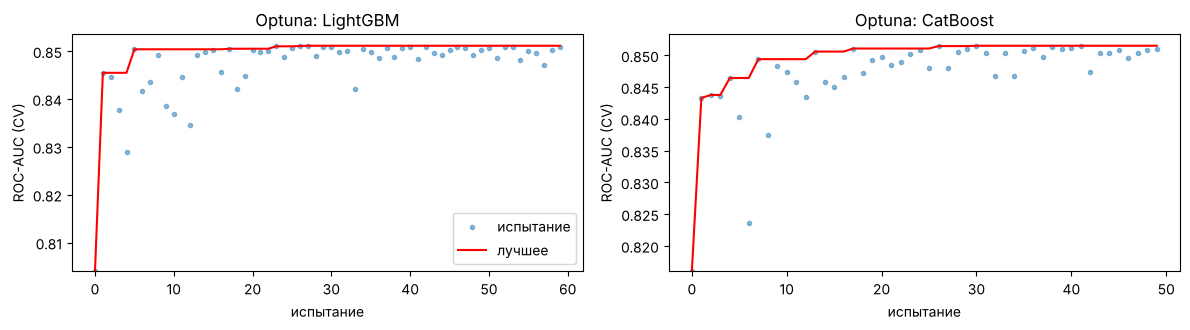

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, (name, st) in zip(axes, [('LightGBM', lgb_study), ('CatBoost', cb_study)]):
    vals = [t.value for t in st.trials]
    ax.plot(vals, 'o', ms=3, alpha=.5, label='испытание')
    ax.plot(np.maximum.accumulate(vals), 'r-', label='лучшее')
    ax.set_title(f'Optuna: {name}'); ax.set_xlabel('испытание'); ax.set_ylabel('ROC-AUC (CV)')
    ax.set_ylim(max(min(vals), 0.80), None)
axes[0].legend()
plt.tight_layout(); plt.savefig('figures/optuna.png', dpi=150); plt.show()

По умолчанию LightGBM переобучается на 5,6 тыс. строк (0,835 — хуже логистической регрессии), CatBoost устойчивее (0,847).
После подбора оба выходят на 0,851: Optuna выбрала маленькие деревья (LightGBM — 7 листьев, CatBoost — глубина 3)
с низким темпом обучения и сильным сэмплированием. Это согласуется с тем, что зависимости в данных простые и почти
аддитивные — недаром логистическая регрессия так близка.

Лучшее значение Optuna — максимум из десятков испытаний на одних и тех же фолдах, поэтому оно оптимистично.
Для честного сравнения моделей переоцениваем лучшие конфигурации на **других** разбиениях
(повторная 5-fold × 3 с другим зерном). Те же разбиения — для логистической регрессии.

In [18]:
rcv2 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)
candidates = {
    'logreg': make_pipeline(FunctionTransformer(build_features), preprocess, LogisticRegression(max_iter=2000)),
    'lightgbm': make_estimator('lightgbm', LGB_BEST),
    'catboost': make_estimator('catboost', CB_BEST, CAT_COLS),
}
recheck = {}
for name, est in candidates.items():
    Xc = X_train if name == 'logreg' else X_train_fe
    recheck[name] = cross_val_score(est, Xc, y_train, cv=rcv2, scoring='roc_auc')
    log_experiment(name, 'base+kept', {}, recheck[name], stage='recheck_cv')
recheck_tab = pd.DataFrame({k: {'ROC-AUC (CV)': v.mean(), 'std': v.std()} for k, v in recheck.items()}).T
for other in ['logreg', 'catboost']:
    d = recheck['lightgbm'] - recheck[other]
    print(f'lightgbm − {other}: {d.mean():+.4f}, std {d.std():.4f}, фолдов с плюсом {(d > 0).sum()}/15')
recheck_tab.round(4)

lightgbm − logreg: +0.0044, std 0.0031, фолдов с плюсом 14/15
lightgbm − catboost: +0.0003, std 0.0017, фолдов с плюсом 10/15


,ROC-AUC (CV),std
logreg,0.8459,0.0106
lightgbm,0.8503,0.0098
catboost,0.8500,0.0096


In [19]:
BEST_KIND = 'lightgbm' if recheck['lightgbm'].mean() >= recheck['catboost'].mean() else 'catboost'
BEST_PARAMS = LGB_BEST if BEST_KIND == 'lightgbm' else CB_BEST
print('Итоговая модель:', BEST_KIND)

Итоговая модель: lightgbm


При переоценке на других разбиениях LightGBM и CatBoost неразличимы (0,8503 и 0,8500, разность +0,0003 при std 0,0017),
оба превосходят логистическую регрессию на +0,004 (в 14 из 15 фолдов). Итоговой выбрана LightGBM: по качеству
равноценна, обучается в десятки раз быстрее (1 с против 36 с на 5 фолдах), модель меньше — это важно для ЛР2.

## Шаг 6. Итоговая оценка на тесте (один раз)

In [20]:
def fit_predict(est, Xtr, Xte):
    return est.fit(Xtr, y_train).predict_proba(Xte)[:, 1]

proba = {
    'dummy': fit_predict(DummyClassifier(strategy='prior'), X_train, X_test),
    'logreg': fit_predict(candidates['logreg'], X_train, X_test),
    'lightgbm': fit_predict(make_estimator('lightgbm', LGB_BEST), X_train_fe, X_test_fe),
    'catboost': fit_predict(make_estimator('catboost', CB_BEST, CAT_COLS), X_train_fe, X_test_fe),
}

def bootstrap_diff(y_true, score_a, score_b, metric, n_boot=1000):
    rng = np.random.default_rng(RANDOM_STATE)
    y_true = np.asarray(y_true)
    score_a, score_b = np.asarray(score_a), np.asarray(score_b)
    a_vals, diffs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        a = metric(y_true[idx], score_a[idx])
        a_vals.append(a)
        diffs.append(a - metric(y_true[idx], score_b[idx]))
    return np.percentile(a_vals, [2.5, 97.5]), np.percentile(diffs, [2.5, 97.5])

rows = []
for name, p in proba.items():
    ci, _ = bootstrap_diff(y_test, p, proba['dummy'], roc_auc_score) if name != 'dummy' else ([.5, .5], None)
    cvm = baseline_cv['dummy'][0].mean() if name == 'dummy' else recheck[name].mean()
    rows.append({'модель': name, 'ROC-AUC CV': cvm, 'ROC-AUC тест': roc_auc_score(y_test, p),
                 '95% ДИ': f'[{ci[0]:.4f}; {ci[1]:.4f}]', 'PR-AUC тест': average_precision_score(y_test, p),
                 'Brier': brier_score_loss(y_test, p), 'log loss': log_loss(y_test, p)})
test_tab = pd.DataFrame(rows).set_index('модель')
test_tab.round(4)

,ROC-AUC CV,ROC-AUC тест,95% ДИ,PR-AUC тест,Brier,log loss
модель,,,,,,
dummy,0.5000,0.5000,[0.5000; 0.5000],0.2654,0.1950,0.5787
logreg,0.8459,0.8418,[0.8189; 0.8623],0.6336,0.1381,0.4206
lightgbm,0.8503,0.8488,[0.8274; 0.8693],0.6646,0.1344,0.4130
catboost,0.8500,0.8476,[0.8256; 0.8682],0.6686,0.1345,0.4127


In [21]:
diff_rows = []
for a, b in [(BEST_KIND, 'logreg'), ('lightgbm', 'catboost'), (BEST_KIND, 'dummy')]:
    for mname, m in [('ROC-AUC', roc_auc_score), ('PR-AUC', average_precision_score)]:
        _, cd = bootstrap_diff(y_test, proba[a], proba[b], m)
        diff_rows.append({'сравнение': f'{a} − {b}', 'метрика': mname,
                          'разность': m(y_test, proba[a]) - m(y_test, proba[b]),
                          '95% ДИ разности': f'[{cd[0]:+.4f}; {cd[1]:+.4f}]',
                          'содержит 0': bool(cd[0] <= 0 <= cd[1])})
diff_tab = pd.DataFrame(diff_rows)
diff_tab.round(4)

,сравнение,метрика,разность,95% ДИ разности,содержит 0
0,lightgbm − logreg,ROC-AUC,0.0070,[+0.0008; +0.0135],False
1,lightgbm − logreg,PR-AUC,0.0310,[+0.0116; +0.0510],False
2,lightgbm − catboost,ROC-AUC,0.0012,[-0.0022; +0.0042],True
3,lightgbm − catboost,PR-AUC,-0.0041,[-0.0129; +0.0049],True
4,lightgbm − dummy,ROC-AUC,0.3488,[+0.3274; +0.3693],False
5,lightgbm − dummy,PR-AUC,0.3991,[+0.3572; +0.4410],False


**Итог на тесте (1409 клиентов, 374 ушедших).** LightGBM: ROC-AUC 0,849 [0,827; 0,869], PR-AUC 0,665.
Кросс-валидационная (0,850) и тестовая оценки согласуются — подбор не переобучился на схеме валидации.
- LightGBM − логрегрессия: ROC-AUC +0,007, интервал [+0,0008; +0,0135] не содержит 0 — превосходство подтверждено,
  но выигрыш небольшой; по PR-AUC +0,031 [+0,012; +0,051].
- LightGBM − CatBoost: интервалы содержат 0 — модели неразличимы.

## Шаг 7. Калибровка и порог

In [22]:
def calibrated_model(method='sigmoid', cat_cols=None):
    est = make_estimator(BEST_KIND, BEST_PARAMS, cat_cols or CAT_COLS)
    return est if method == 'none' else CalibratedClassifierCV(est, method=method, cv=5)

# out-of-fold прогнозы на обучающей выборке: сырые и откалиброванные
oof_raw = cross_val_predict(make_estimator(BEST_KIND, BEST_PARAMS, CAT_COLS), X_train_fe, y_train,
                            cv=cv, method='predict_proba')[:, 1]
oof_cal = {m: cross_val_predict(calibrated_model(m), X_train_fe, y_train, cv=cv, method='predict_proba')[:, 1]
           for m in ['sigmoid', 'isotonic']}
oof_cal['none'] = oof_raw
calib_tab = pd.DataFrame({
    name: {'Brier OOF': brier_score_loss(y_train, p), 'log loss OOF': log_loss(y_train, p),
           'ROC-AUC OOF': roc_auc_score(y_train, p), 'средний прогноз': p.mean()}
    for name, p in [('без калибровки', oof_raw), ('sigmoid', oof_cal['sigmoid']), ('isotonic', oof_cal['isotonic'])]}).T
print('Фактическая доля ушедших (train):', round(y_train.mean(), 4))
calib_tab.round(4)

Фактическая доля ушедших (train): 0.2654


,Brier OOF,log loss OOF,ROC-AUC OOF,средний прогноз
без калибровки,0.133,0.4107,0.8503,0.2648
sigmoid,0.133,0.4104,0.8503,0.2655
isotonic,0.133,0.4172,0.8491,0.2653


Метод калибровки: none (none — калибровка не дала заметного улучшения)
Тест: Brier сырой 0.1344 | откалиброванной 0.1344 | ROC-AUC откалиброванной 0.8488


Brier на тесте: {'sigmoid': 0.1342, 'isotonic': 0.1342, 'none': 0.1344}


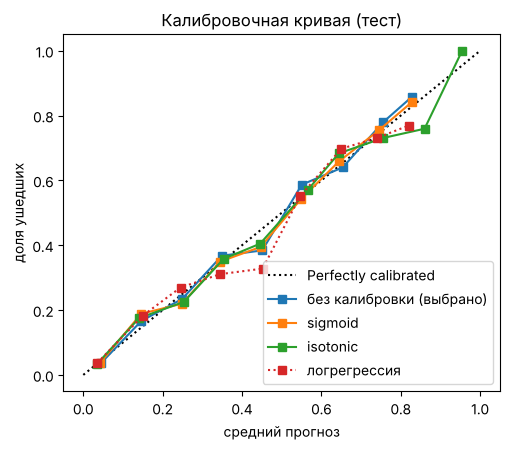

In [23]:
# калибровку применяем, только если она заметно (более чем на 1 %) улучшает Brier score на OOF-прогнозах
# и не ухудшает log loss; иначе лишний слой только усложняет модель
best_cal = calib_tab.drop(index='без калибровки')['Brier OOF'].idxmin()
improves = (calib_tab.loc[best_cal, 'Brier OOF'] < 0.99 * calib_tab.loc['без калибровки', 'Brier OOF']
            and calib_tab.loc[best_cal, 'log loss OOF'] <= calib_tab.loc['без калибровки', 'log loss OOF'])
CAL_METHOD = best_cal if improves else 'none'
proba_oof = oof_cal[CAL_METHOD]
calibrated = calibrated_model(CAL_METHOD).fit(X_train_fe, y_train)
proba_cal_test = calibrated.predict_proba(X_test_fe)[:, 1]
print('Метод калибровки:', CAL_METHOD, '(none — калибровка не дала заметного улучшения)')
print('Тест: Brier сырой', round(brier_score_loss(y_test, proba[BEST_KIND]), 4),
      '| откалиброванной', round(brier_score_loss(y_test, proba_cal_test), 4),
      '| ROC-AUC откалиброванной', round(roc_auc_score(y_test, proba_cal_test), 4))

fig, ax = plt.subplots(figsize=(5.2, 4.6))
test_cal = {m: calibrated_model(m).fit(X_train_fe, y_train).predict_proba(X_test_fe)[:, 1] for m in ['sigmoid', 'isotonic']}
test_cal['none'] = proba[BEST_KIND]
print('Brier на тесте:', {m: round(brier_score_loss(y_test, p), 4) for m, p in test_cal.items()})
for m, lbl in [('none', 'без калибровки'), ('sigmoid', 'sigmoid'), ('isotonic', 'isotonic')]:
    CalibrationDisplay.from_predictions(y_test, test_cal[m], n_bins=10, name=lbl + (' (выбрано)' if m == CAL_METHOD else ''), ax=ax)
CalibrationDisplay.from_predictions(y_test, proba['logreg'], n_bins=10, name='логрегрессия', ax=ax, ls=':')
ax.set_title('Калибровочная кривая (тест)'); ax.set_xlabel('средний прогноз'); ax.set_ylabel('доля ушедших')
plt.tight_layout(); plt.savefig('figures/calibration.png', dpi=150); plt.show()

Модель **уже откалибрована**: средний прогноз 0,265 совпадает с долей ушедших, кривая лежит на диагонали, а Brier score
сырой модели (0,1330 OOF) не улучшается ни sigmoid-, ни isotonic-калибровкой (разница в 4-м знаке; isotonic ещё и
ухудшает log loss: 0,417 против 0,411). Причина — бустинг обучается на log loss без весов классов и пересэмплирования.
Поэтому калибровочная надстройка не применяется (`CAL_METHOD = 'none'`).

In [24]:
def total_cost(y_true, proba_, t, c_fn=C_FN, c_fp=C_FP):
    y_true, pred = np.asarray(y_true), np.asarray(proba_) >= t
    fn = np.sum(~pred & (y_true == 1))
    fp = np.sum(pred & (y_true == 0))
    return c_fn * fn + c_fp * fp

grid = np.round(np.linspace(0.01, 0.99, 99), 2)
costs_oof = np.array([total_cost(y_train, proba_oof, t) for t in grid])
T_BEST = float(grid[int(np.argmin(costs_oof))])
T_THEORY = C_FP / (C_FP + C_FN)
print(f'Порог по OOF: {T_BEST:.2f} | теоретический: {T_THEORY:.3f}')
# стоимость почти плоская возле минимума — смотрим диапазон порогов в пределах 1 % от минимума
near = grid[costs_oof <= costs_oof.min() * 1.01]
print(f'Пороги со стоимостью в пределах 1 % от минимума: {near.min():.2f}–{near.max():.2f}')
# порог по сырым (некалиброванным) OOF-прогнозам — для сравнения
t_raw = float(grid[int(np.argmin([total_cost(y_train, oof_raw, t) for t in grid]))])
print(f'Порог по сырым OOF-прогнозам: {t_raw:.2f}')

Порог по OOF: 0.10 | теоретический: 0.118
Пороги со стоимостью в пределах 1 % от минимума: 0.08–0.17
Порог по сырым OOF-прогнозам: 0.10


Порог, найденный по OOF-прогнозам, — 0,10, теоретический t* = 800 / 6800 = 0,118. Близость подтверждает калибровку.
Кривая стоимости около минимума очень пологая: пороги от 0,08 до 0,17 дают стоимость в пределах 1 % от минимума,
так что расхождение 0,10 и 0,118 несущественно.

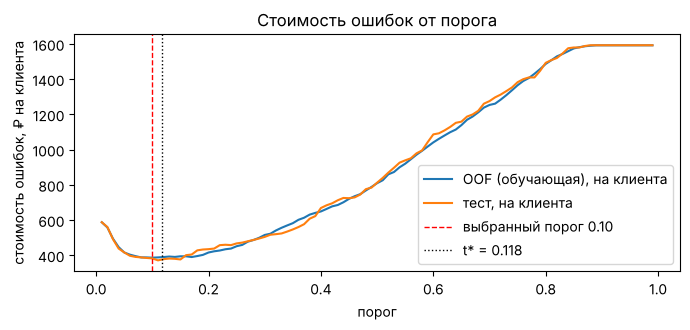

In [25]:
costs_test = np.array([total_cost(y_test, proba_cal_test, t) for t in grid])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(grid, costs_oof / len(y_train), label='OOF (обучающая), на клиента')
ax.plot(grid, costs_test / len(y_test), label='тест, на клиента')
ax.axvline(T_BEST, color='r', ls='--', lw=1, label=f'выбранный порог {T_BEST:.2f}')
ax.axvline(T_THEORY, color='k', ls=':', lw=1, label=f't* = {T_THEORY:.3f}')
ax.set_xlabel('порог'); ax.set_ylabel('стоимость ошибок, ₽ на клиента'); ax.legend(); ax.set_title('Стоимость ошибок от порога')
plt.tight_layout(); plt.savefig('figures/cost_threshold.png', dpi=150); plt.show()

In [26]:
def strategy_row(name, pred):
    pred = np.asarray(pred).astype(bool)
    yt = y_test.values
    tp, fp = int(np.sum(pred & (yt == 1))), int(np.sum(pred & (yt == 0)))
    fn, tn = int(np.sum(~pred & (yt == 1))), int(np.sum(~pred & (yt == 0)))
    cost = C_FN * fn + C_FP * fp
    return {'стратегия': name, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'precision': tp / (tp + fp) if tp + fp else np.nan, 'recall': tp / (tp + fn),
            'доля отобранных, %': 100 * pred.mean(), 'стоимость, тыс. ₽': cost / 1000,
            'на клиента, ₽': cost / len(yt)}

strategies = pd.DataFrame([
    strategy_row('никому не предлагать скидку', np.zeros(len(y_test))),
    strategy_row('скидка всем', np.ones(len(y_test))),
    strategy_row('порог 0,50', proba_cal_test >= 0.5),
    strategy_row(f'порог {T_BEST:.2f} (по стоимости)', proba_cal_test >= T_BEST),
    strategy_row(f'логрегрессия, порог {T_BEST:.2f}', proba['logreg'] >= T_BEST),
]).set_index('стратегия')
saving = strategies.loc['никому не предлагать скидку', 'стоимость, тыс. ₽'] - strategies['стоимость, тыс. ₽']
strategies['экономия vs «никому», тыс. ₽'] = saving
print('Матрица ошибок при выбранном пороге:\n', confusion_matrix(y_test, proba_cal_test >= T_BEST))
strategies.round(3)

Матрица ошибок при выбранном пороге:
 [[504 531]
 [ 19 355]]


,TP,FP,FN,TN,precision,recall,"доля отобранных, %","стоимость, тыс. ₽","на клиента, ₽","экономия vs «никому», тыс. ₽"
стратегия,,,,,,,,,,
никому не предлагать скидку,0,0,374,1035,NaN,0.000,0.000,2244.0,1592.619,0.0
скидка всем,374,1035,0,0,0.265,1.000,100.000,828.0,587.651,1416.0
"порог 0,50",196,96,178,939,0.671,0.524,20.724,1144.8,812.491,1099.2
порог 0.10 (по стоимости),355,531,19,504,0.401,0.949,62.881,538.8,382.399,1705.2
"логрегрессия, порог 0.10",354,517,20,518,0.406,0.947,61.817,533.6,378.708,1710.4


In [27]:
# бутстреп-интервал экономии выбранной стратегии относительно порога 0,5 и относительно логрегрессии
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.values
d05, dlr = [], []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    c_best = total_cost(yt[idx], proba_cal_test[idx], T_BEST)
    d05.append(total_cost(yt[idx], proba_cal_test[idx], 0.5) - c_best)
    dlr.append(total_cost(yt[idx], proba['logreg'][idx], T_BEST) - c_best)
print('Экономия порога T_BEST относительно 0,5, тыс. ₽: 95% ДИ', np.round(np.percentile(d05, [2.5, 97.5]) / 1000, 1))
print('Экономия бустинга относительно логрегрессии при том же пороге, тыс. ₽: 95% ДИ',
      np.round(np.percentile(dlr, [2.5, 97.5]) / 1000, 1))

Экономия порога T_BEST относительно 0,5, тыс. ₽: 95% ДИ [458.8 750.8]
Экономия бустинга относительно логрегрессии при том же пороге, тыс. ₽: 95% ДИ [-36.4  24.4]


**Сравнение стратегий на тесте.**
- Без модели («никому») потери 2,24 млн ₽; «скидка всем» — 0,83 млн ₽: даже без модели скидка выгодна, т. к. пропуск
  уходящего в 7,5 раза дороже скидки.
- Порог 0,5 — 1,14 млн ₽: он ловит лишь 52 % уходящих и хуже, чем «скидка всем». Порог по умолчанию игнорирует цену ошибок.
- Порог 0,10 — **0,54 млн ₽** (−76 % относительно «никому», −35 % относительно «скидка всем»): скидку получают 63 %
  клиентов, найдено 95 % уходящих. Экономия против порога 0,5 — 0,61 млн ₽, ДИ [0,46; 0,75] млн ₽.
- Логистическая регрессия с тем же порогом даёт практически ту же стоимость (0,53 млн ₽, ДИ разности [−36; +24] тыс. ₽):
  **в деньгах выигрыш бустинга не подтверждается**. Главный эффект даёт правильный порог, а не выбор алгоритма.

## Шаг 8. Интерпретация (SHAP)
Модель не оборачивалась в калибровку (см. шаг 7), поэтому SHAP считается прямо для итоговой LightGBM; вклады — в логитах.

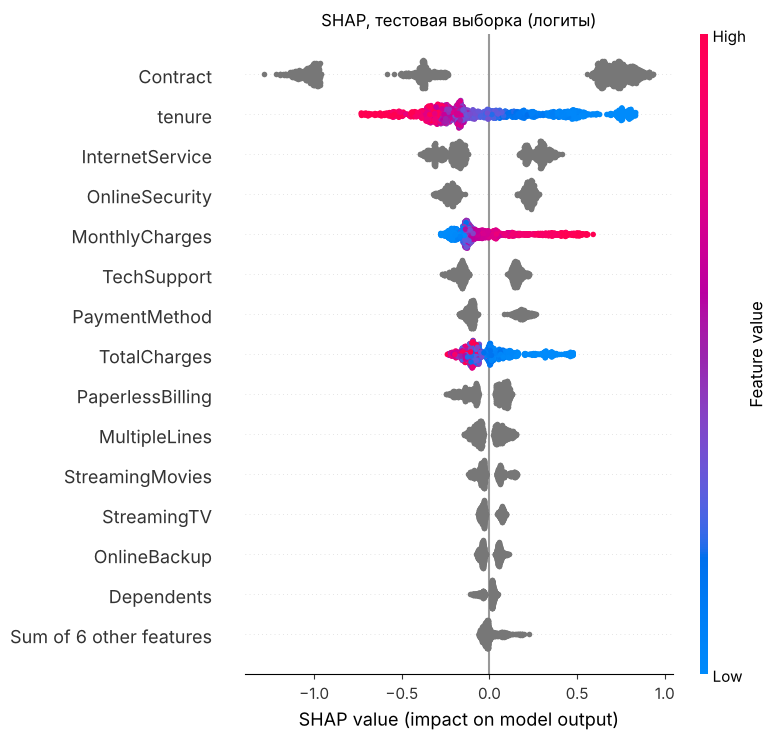

In [28]:
base_model = make_estimator(BEST_KIND, BEST_PARAMS, CAT_COLS).fit(X_train_fe, y_train)
prep, booster = base_model[0], base_model[-1]
X_test_prep = prep.transform(X_test_fe)
X_expl = X_test_prep.sample(min(2000, len(X_test_prep)), random_state=RANDOM_STATE)

if BEST_KIND == 'lightgbm':
    sv_all = shap.TreeExplainer(booster)(X_test_prep)
else:
    from catboost import Pool
    booster = booster.model_
    raw_sv = booster.get_feature_importance(Pool(X_test_prep, cat_features=CAT_COLS), type='ShapValues')
    sv_all = shap.Explanation(values=raw_sv[:, :-1], base_values=raw_sv[:, -1],
                              data=X_test_prep.values, feature_names=list(X_test_prep.columns))
pos = {idx: i for i, idx in enumerate(X_test_prep.index)}
sv = sv_all[[pos[i] for i in X_expl.index]]

plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('SHAP, тестовая выборка (логиты)'); plt.tight_layout()
plt.savefig('figures/shap_beeswarm.png', dpi=150, bbox_inches='tight'); plt.show()

In [29]:
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=X_test_prep.columns)
if BEST_KIND == 'lightgbm':
    gain = pd.Series(booster.booster_.feature_importance('gain'), index=booster.booster_.feature_name())
    gain.index = X_test_prep.columns
else:
    gain = pd.Series(booster.get_feature_importance(), index=X_test_prep.columns)
imp = pd.DataFrame({'mean |SHAP|': mean_abs, 'gain, %': 100 * gain / gain.sum()})
imp['ранг SHAP'] = imp['mean |SHAP|'].rank(ascending=False).astype(int)
imp['ранг gain'] = imp['gain, %'].rank(ascending=False).astype(int)
imp = imp.sort_values('ранг SHAP')
imp.round(3).head(15)

,mean |SHAP|,"gain, %",ранг SHAP,ранг gain
Contract,0.727,36.941,1,1
tenure,0.325,12.941,2,2
InternetService,0.254,9.244,3,4
OnlineSecurity,0.225,9.713,4,3
MonthlyCharges,0.168,5.928,5,6
TechSupport,0.163,5.553,6,7
PaymentMethod,0.137,3.929,7,8
TotalCharges,0.116,7.193,8,5
PaperlessBilling,0.097,2.097,9,9
MultipleLines,0.073,1.395,10,10


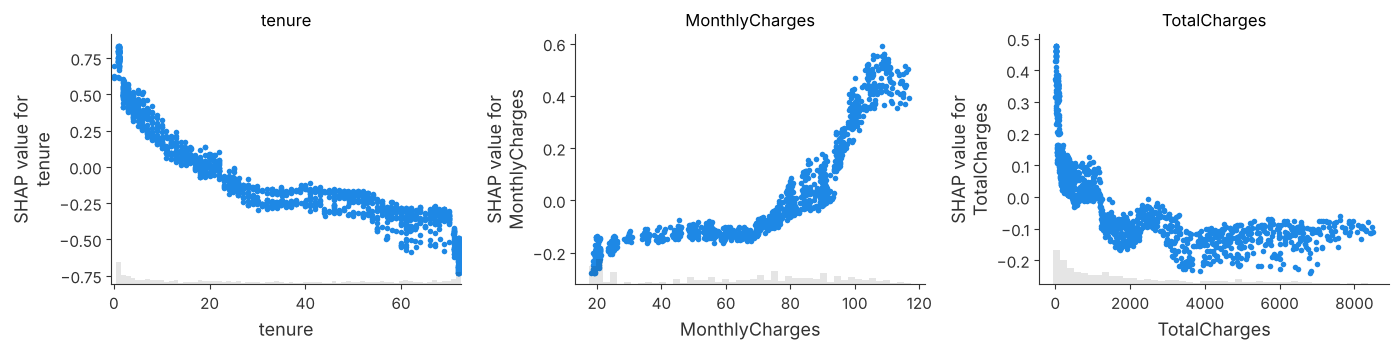


Contract: средний SHAP по значениям
                  mean  size
Two year       -1.035   336
One year       -0.370   300
Month-to-month  0.732   773

InternetService: средний SHAP по значениям
               mean  size
No          -0.245   312
DSL         -0.228   484
Fiber optic  0.278   613

OnlineSecurity: средний SHAP по значениям
                       mean  size
No internet service -0.244   312
Yes                 -0.210   396
No                   0.226   701


In [30]:
KEY = imp.index[:3].tolist()
num_key = [c for c in imp.index if c not in CAT_COLS][:3]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, c in zip(axes, num_key):
    shap.plots.scatter(sv[:, c], ax=ax, show=False)
    ax.set_title(c)
plt.tight_layout(); plt.savefig('figures/shap_scatter.png', dpi=150, bbox_inches='tight'); plt.show()

# средний вклад по значениям ключевых категориальных признаков
cat_key = [c for c in imp.index if c in CAT_COLS][:3]
for c in cat_key:
    s = pd.Series(sv[:, c].values, index=X_expl[c].astype(str).values).groupby(level=0).agg(['mean', 'size'])
    print(f'\n{c}: средний SHAP по значениям\n', s.sort_values('mean').round(3))

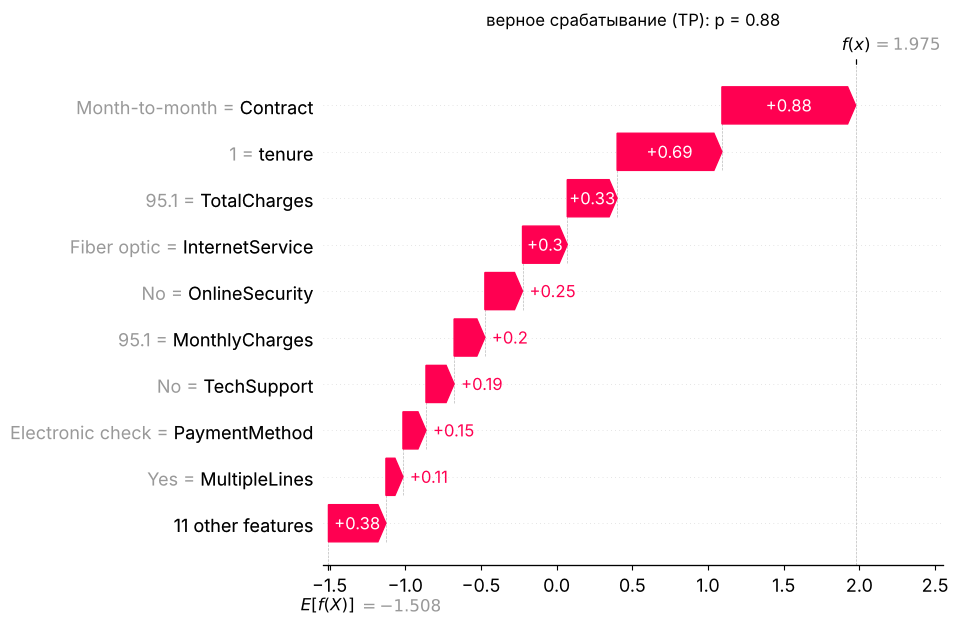

верное срабатывание (TP) 
 {'tenure': 1, 'Contract': 'Month-to-month', 'InternetService': 'Fiber optic', 'PaymentMethod': 'Electronic check', 'MonthlyCharges': 95.1, 'TotalCharges': '95.1', 'TechSupport': 'No', 'OnlineSecurity': 'No'}


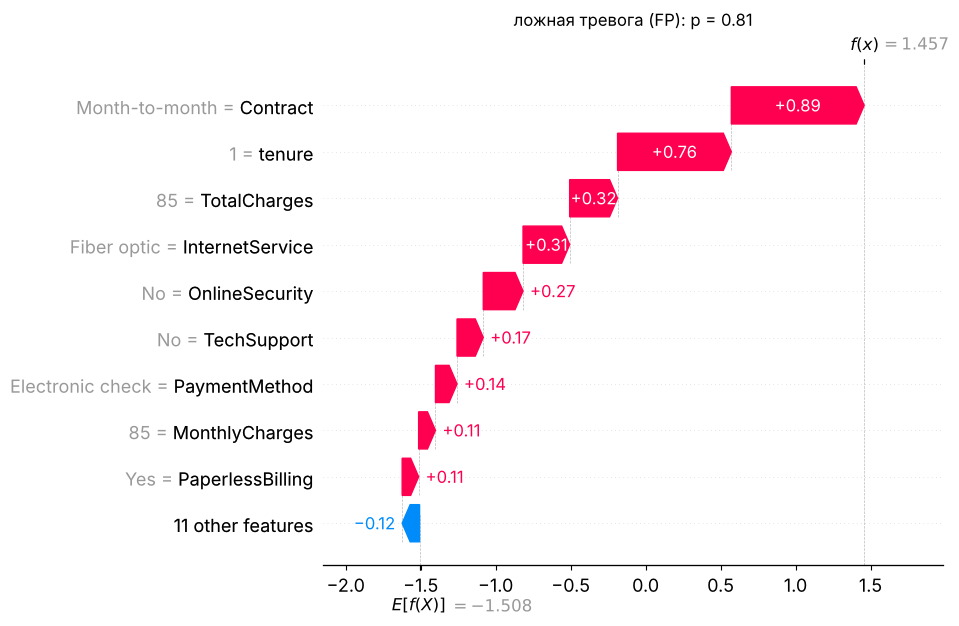

ложная тревога (FP) 
 {'tenure': 1, 'Contract': 'Month-to-month', 'InternetService': 'Fiber optic', 'PaymentMethod': 'Electronic check', 'MonthlyCharges': 85.0, 'TotalCharges': '85', 'TechSupport': 'No', 'OnlineSecurity': 'No'}


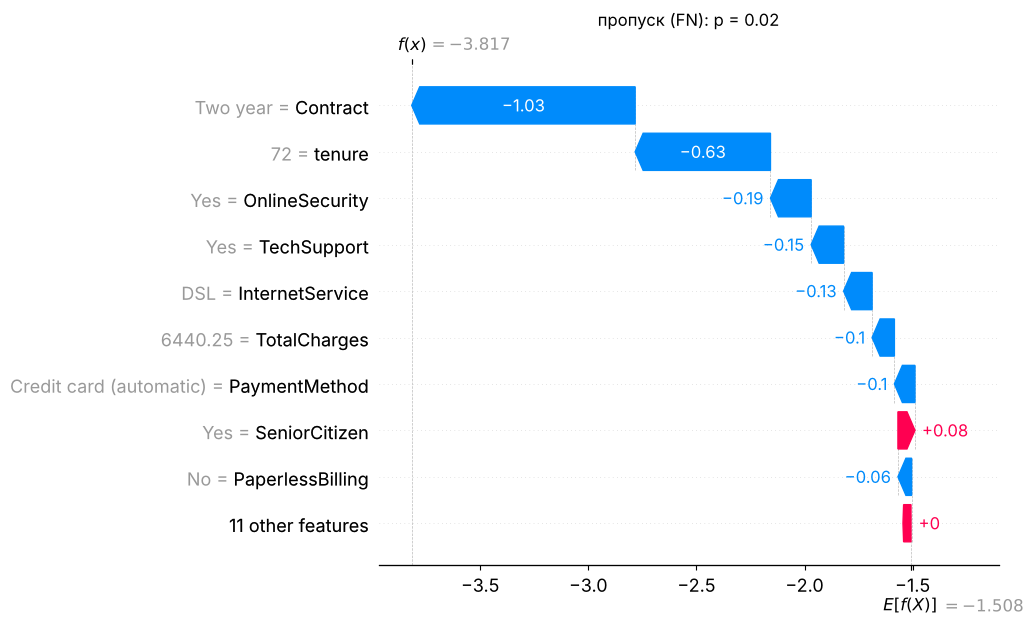

пропуск (FN) 
 {'tenure': 72, 'Contract': 'Two year', 'InternetService': 'DSL', 'PaymentMethod': 'Credit card (automatic)', 'MonthlyCharges': 92.45, 'TotalCharges': '6440.25', 'TechSupport': 'Yes', 'OnlineSecurity': 'Yes'}


In [31]:
pred_test = proba_cal_test >= T_BEST
order = pd.Series(proba_cal_test, index=X_test.index)
cases = {
    'верное срабатывание (TP)': order[(pred_test) & (y_test.values == 1)].idxmax(),
    'ложная тревога (FP)': order[(pred_test) & (y_test.values == 0)].idxmax(),
    'пропуск (FN)': order[(~pred_test) & (y_test.values == 1)].idxmin(),
}
for i, (title, idx) in enumerate(cases.items()):
    plt.figure()
    shap.plots.waterfall(sv_all[pos[idx]], max_display=10, show=False)
    plt.title(f'{title}: p = {proba_cal_test[pos[idx]]:.2f}')
    plt.savefig(f'figures/shap_waterfall_{i}.png', dpi=150, bbox_inches='tight'); plt.show()
    print(title, '\n', X_test.loc[idx, ['tenure', 'Contract', 'InternetService', 'PaymentMethod',
                                        'MonthlyCharges', 'TotalCharges', 'TechSupport', 'OnlineSecurity']].to_dict())

**Интерпретация.**
- Главный фактор — тип договора: помесячный договор сдвигает прогноз в сторону ухода (в среднем +0,73 логита),
  двухлетний — в сторону удержания (−1,04).
- Стаж (`tenure`) — второй: первые месяцы дают до +0,8 логита, после ~2 лет вклад отрицательный. `TotalCharges`
  повторяет этот эффект (сильно коррелирует со стажем), поэтому их вклад делится между собой.
- Оптоволокно повышает риск (+0,28), а наличие онлайн-защиты и техподдержки снижает его (−0,2): клиенты, вложившиеся в
  дополнительные услуги, «привязаны» к оператору.
- Высокий ежемесячный платёж (> 70–80 у. е.) повышает риск — до +0,5 логита при платеже > 100.

**SHAP против gain.** Первые два места совпадают (Contract, tenure), дальше расхождения: `TotalCharges` по gain пятый,
по SHAP восьмой. Gain завышает непрерывные признаки с множеством точек разреза и учитывает разбиения, «использованные»
при обучении, а SHAP — фактическое влияние на прогноз; кроме того, коррелированные `tenure` и `TotalCharges` делят вклад.

**Разбор ошибок.** Ложная тревога (p = 0,81) по признакам неотличима от верного срабатывания: новый клиент (1 мес.),
помесячный договор, оптоволокно, электронный чек, без защиты. Модель тут не «ошиблась» — у неё нет информации,
отличающей остающихся из этой группы (качество связи, обращения в поддержку). Пропуск (p = 0,02) — клиент с 6-летним стажем
и двухлетним договором со всеми услугами: такие уходы (переезд, внешние причины) по этим данным непредсказуемы.

## Дополнительное задание: справедливость по чувствительным признакам
Сравниваем по группам пола и возраста (SeniorCitizen) долю положительных решений (скидку получает),
recall (долю найденных уходящих) и precision при выбранном пороге. Затем проверяем, что даёт исключение
чувствительных признаков из модели.

In [32]:
def fairness_table(pred, groups):
    rows = []
    for gname, gcol in groups.items():
        for v in sorted(X_test[gcol].unique()):
            m = (X_test[gcol] == v).values
            yt_, pr_ = y_test.values[m], pred[m]
            rows.append({'признак': gname, 'группа': v, 'клиентов': int(m.sum()),
                         'доля ушедших, %': 100 * yt_.mean(), 'доля со скидкой, %': 100 * pr_.mean(),
                         'recall': pr_[yt_ == 1].mean(), 'precision': yt_[pr_].mean() if pr_.any() else np.nan,
                         'ROC-AUC': roc_auc_score(yt_, proba_cal_test[m])})
    return pd.DataFrame(rows)

GROUPS = {'пол': 'gender', 'пенсионер': 'SeniorCitizen'}
fair = fairness_table(pred_test, GROUPS)
fair.round(3)

,признак,группа,клиентов,"доля ушедших, %","доля со скидкой, %",recall,precision,ROC-AUC
0,пол,Female,687,28.093,63.610,0.943,0.416,0.848
1,пол,Male,722,25.069,62.188,0.956,0.385,0.850
2,пенсионер,0,1187,23.252,58.804,0.935,0.370,0.850
3,пенсионер,1,222,44.144,84.685,0.990,0.516,0.787


In [33]:
SENSITIVE = ['gender', 'SeniorCitizen']
Xtr_ns, Xte_ns = X_train_fe.drop(columns=SENSITIVE), X_test_fe.drop(columns=SENSITIVE)
m_ns = calibrated_model(CAL_METHOD, F.cat_columns(Xtr_ns)).fit(Xtr_ns, y_train)
p_ns = m_ns.predict_proba(Xte_ns)[:, 1]
print('Без пола и SeniorCitizen: ROC-AUC тест', round(roc_auc_score(y_test, p_ns), 4),
      '| с ними', round(roc_auc_score(y_test, proba_cal_test), 4))
print('Стоимость при пороге', T_BEST, ': без —', total_cost(y_test, p_ns, T_BEST) / 1000,
      'тыс. ₽ | с ними —', total_cost(y_test, proba_cal_test, T_BEST) / 1000, 'тыс. ₽')
fair_ns = fairness_table(p_ns >= T_BEST, GROUPS)
fair_ns[['признак', 'группа', 'доля со скидкой, %', 'recall', 'precision']].round(3)

Без пола и SeniorCitizen: ROC-AUC тест 0.8479 | с ними 0.8488
Стоимость при пороге 0.1 : без — 536.0 тыс. ₽ | с ними — 538.8 тыс. ₽


,признак,группа,"доля со скидкой, %",recall,precision
0,пол,Female,64.047,0.948,0.416
1,пол,Male,62.465,0.956,0.384
2,пенсионер,0,59.478,0.938,0.367
3,пенсионер,1,83.333,0.990,0.524


**Справедливость.** По полу модель ведёт себя одинаково: доля получающих скидку 63,6 % и 62,2 %, recall 0,94 и 0,96.
Пенсионеры получают скидку чаще (84,7 % против 58,8 %), но и уходят они почти вдвое чаще (44,1 % против 23,3 %),
а recall у обеих групп высок (0,99 и 0,94); при этом ранжирование среди пенсионеров хуже (ROC-AUC 0,787 против 0,850).
Исключение пола и `SeniorCitizen` почти не меняет качество (ROC-AUC 0,848 против 0,849) и стоимость (536 против 539 тыс. ₽),
а доли по группам остаются прежними: возраст «просачивается» через связанные признаки (тип договора, способ оплаты).
Поскольку решение — **предложить скидку** (благо, а не отказ), более частые предложения пенсионерам не дискриминационны.
Меры: исключить пол и `SeniorCitizen` из модели для ЛР2 (цена — несущественна), контролировать долю предложений и
recall по группам при мониторинге; если бы решение было ограничительным — выравнивать пороги по группам.

## Шаг 9. Сохранение модели

In [34]:
# add_features из модуля features.py (а не функция ноутбука) — иначе модель не загрузится в другом процессе
final_pipeline = make_pipeline(FunctionTransformer(F.add_features, kw_args={'drop': DROP_FEATURES}),
                               calibrated_model(CAL_METHOD))
final_pipeline.fit(X_train, y_train)
bundle = {'pipeline': final_pipeline, 'threshold': T_BEST, 'model_kind': BEST_KIND, 'calibration': CAL_METHOD,
          'params': BEST_PARAMS, 'drop_features': DROP_FEATURES, 'costs': {'C_FN': C_FN, 'C_FP': C_FP},
          'input_columns': list(X_train.columns), 'sklearn_version': sklearn.__version__,
          'test_roc_auc': float(roc_auc_score(y_test, final_pipeline.predict_proba(X_test)[:, 1]))}
joblib.dump(bundle, 'model.joblib')
print('model.joblib:', round(os.path.getsize('model.joblib') / 1e6, 2), 'МБ | тест ROC-AUC', round(bundle['test_roc_auc'], 4))

def column_schema(s):
    if pd.api.types.is_numeric_dtype(s):
        return {'type': 'integer' if pd.api.types.is_integer_dtype(s) else 'number',
                'min': float(s.min()), 'max': float(s.max()), 'nullable': bool(s.isna().any())}
    return {'type': 'category', 'values': sorted(s.dropna().astype(str).unique().tolist())}

schema_X = X_train.drop(columns=['customerID'])
schema = {
    'description': 'Вход модели оттока Telco (ЛР1, вариант 1). Одна строка — один клиент на дату среза.',
    'target': {'name': 'Churn', 'positive': 'Yes', 'output': 'вероятность ухода; решение = proba >= threshold'},
    'threshold': T_BEST,
    'optional_columns': ['customerID'],
    'features': {col: column_schema(schema_X[col]) for col in schema_X.columns},
}
schema['features']['TotalCharges'] = {'type': 'number (строка допускается, пустая строка = 0 при tenure = 0)',
                                      'min': 0.0, 'max': float(F.clean(X_train)['TotalCharges'].max()),
                                      'nullable': True}
with open('input_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)
print('input_schema.json:', len(schema['features']), 'признаков')

model.joblib: 0.32 МБ | тест ROC-AUC 0.8488
input_schema.json: 19 признаков


In [35]:
loaded = joblib.load('model.joblib')
assert np.allclose(loaded['pipeline'].predict_proba(X_test)[:, 1], final_pipeline.predict_proba(X_test)[:, 1])
# проверка в отдельном процессе: загрузка требует только features.py
import subprocess, sys
X_test.head(5).to_csv('figures/_sample.csv', index=False)
code = ("import joblib, pandas as pd; b = joblib.load('model.joblib'); "
        "x = pd.read_csv('figures/_sample.csv'); print(b['pipeline'].predict_proba(x)[:, 1].round(6).tolist())")
out = subprocess.run([sys.executable, '-c', code], capture_output=True, text=True, check=True).stdout
other = np.array(json.loads(out))
assert np.allclose(other, final_pipeline.predict_proba(X_test.head(5))[:, 1], atol=1e-6)
os.remove('figures/_sample.csv')
print('Прогнозы после загрузки совпадают (в этом и в отдельном процессе):', other)
log = pd.read_csv('experiments.csv')
print('experiments.csv:', len(log), 'записей;', log.groupby(['stage', 'model'], dropna=False).size().to_dict())

Прогнозы после загрузки совпадают (в этом и в отдельном процессе): [0.038133 0.762221 0.07365  0.335906 0.029109]
experiments.csv: 138 записей; {('ablation', 'lightgbm'): 17, ('ablation', 'logreg'): 2, ('baseline', 'dummy'): 2, ('baseline', 'logreg'): 2, ('default', 'catboost'): 1, ('default', 'lightgbm'): 1, ('optuna', 'catboost'): 50, ('optuna', 'lightgbm'): 60, ('recheck_cv', 'catboost'): 1, ('recheck_cv', 'lightgbm'): 1, ('recheck_cv', 'logreg'): 1}


Пайплайн «признаки + LightGBM» сохранён вместе с порогом 0,10 и метаданными (`model.joblib`, 0,3 МБ).
Загрузка в отдельном процессе требует только модуля `features.py`; прогнозы совпадают. `input_schema.json` описывает
19 входных признаков (диапазоны числовых и допустимые значения категориальных), `experiments.csv` — 138 записей
(baseline, абляция, 60 испытаний Optuna для LightGBM, 50 — для CatBoost, переоценка лучших конфигураций).

## Выводы для заказчика
1. Риск ухода предсказуем: среди 10 % клиентов с наибольшим прогнозом уходят 77 %, среди 25 % — 63 % (в среднем — 26,5 %).
2. Предлагать скидку по прогнозу выгодно: при пороге 10 % потери от оттока и лишних скидок на тестовой выборке —
   0,54 млн ₽ против 2,24 млн ₽ без кампании и 0,83 млн ₽ при скидке всем. Скидку получают 63 % клиентов, находится 95 % уходящих.
3. Группа риска — новые клиенты на помесячном договоре с оптоволокном и оплатой электронным чеком, без услуг защиты и
   поддержки. Перевод на годовой договор и подключение техподдержки — главные рычаги удержания (это гипотезы для пилота,
   а не доказанная причинность).
4. Простая модель (логистическая регрессия) в деньгах даёт почти тот же результат — важнее правильно выбрать порог,
   чем алгоритм.
5. Ограничения: все суммы условны (C_FN = 6000 ₽, C_FP = 800 ₽) и предполагают, что скидка удерживает каждого уходящего;
   реальный эффект покажет только пилот с контрольной группой. Модель обучена на одном срезе — нужен мониторинг и переобучение.